# Inférence test

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from basic_pitch.inference import predict
from basic_pitch import FilenameSuffix, build_icassp_2022_model_path


In [3]:
enregistrement_midi = False

model_path = build_icassp_2022_model_path(FilenameSuffix.onnx)
model_output, midi_data, note_events = predict("basic-pitch/tests/resources/vocadito_14.wav", model_or_model_path=model_path)
midi_data.write("vocadito_14.mid")

if(enregistrement_midi):
    midi_data.write("vocadito_14.mid")

Predicting MIDI for basic-pitch/tests/resources/vocadito_14.wav...


C:\Users\amaur\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


# Représentation des sorties du modèle

(1049, 88)


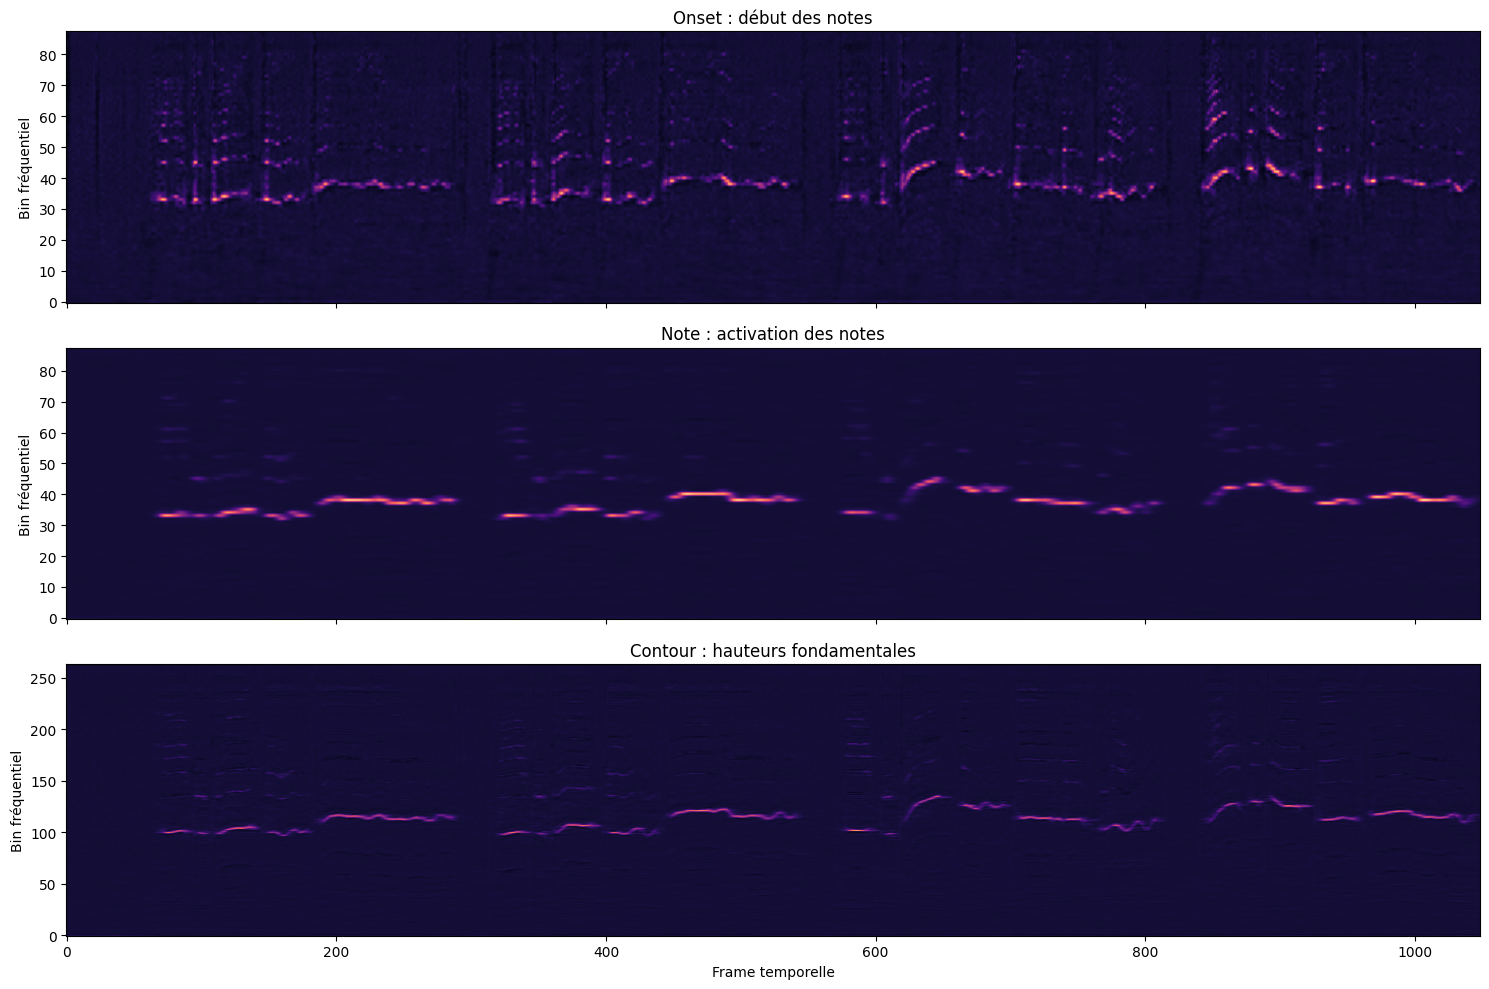

In [ ]:
print(model_output["onset"].shape) #1056 trames et 88 demi ton.

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

names = ["onset", "note", "contour"]
titles = [
    "Onset : début des notes",
    "Note : activation des notes",
    "Contour : hauteurs fondamentales"
]

for ax, name, title in zip(axes, names, titles):
    data = model_output[name]

    ax.imshow(
        data.T,
        origin="lower",
        aspect="auto",
        cmap="magma",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.set_ylabel("Bin fréquentiel")

axes[-1].set_xlabel("Frame temporelle")

plt.tight_layout()
plt.show()



$Y_o[t,n] = P(\text{la note }n\text{ commence à }t)$

$Y_n[t,n] = P(\text{la note }n\text{ est active à }t)$

$Y_p$ : quelle est la fréquence précise de la note ?
